In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df_clean = pd.read_csv("df_clean.csv")

print("Dimensiones del dataset:", df_clean.shape)
df_clean.head()

Dimensiones del dataset: (1000, 8)


,CODUSU,REGION,IX_TOT,NIVEL_ED,ITF,DECIFR,IV12_3,II7
0,HOG_EPH_2026_0001,40,3,3.0,198127.28,1.0,1.0,1.0
1,HOG_EPH_2026_0002,44,6,4.0,NaN,NaN,1.0,2.0
2,HOG_EPH_2026_0003,42,5,4.0,1392730.43,9.0,1.0,1.0
3,HOG_EPH_2026_0004,41,4,4.0,420184.85,3.0,2.0,2.0
4,HOG_EPH_2026_0005,1,2,2.0,108507.59,1.0,2.0,1.0


In [6]:
# Seleccionar las dos variables que vamos a estudiar
df_h1 = df_clean[["ITF", "IV12_3"]]

# Eliminar las filas que tienen datos faltantes
df_h1 = df_h1.dropna()

# Mostrar cuántos registros quedaron
print("Cantidad de hogares:", len(df_h1))

Cantidad de hogares: 902


In [7]:
df_h1["Grupo_ingresos"] = pd.qcut(
    df_h1["ITF"],
    q=4,
    labels=["Bajo", "Medio-bajo", "Medio-alto", "Alto"]
)

df_h1.head()

,ITF,IV12_3,Grupo_ingresos
0,198127.28,1.0,Bajo
2,1392730.43,1.0,Alto
3,420184.85,2.0,Medio-bajo
4,108507.59,2.0,Bajo
5,1874973.06,1.0,Alto


In [8]:
tabla = pd.crosstab(
    df_h1["Grupo_ingresos"],
    df_h1["IV12_3"]
)

tabla


IV12_3,1.0,2.0
Grupo_ingresos,,
Bajo,98,128
Medio-bajo,138,87
Medio-alto,154,71
Alto,188,38


In [9]:
#calculamos porcentajes
porcentajes = pd.crosstab(
    df_h1["Grupo_ingresos"],
    df_h1["IV12_3"],
    normalize="index"
) * 100

porcentajes.round(2)

IV12_3,1.0,2.0
Grupo_ingresos,,
Bajo,43.36,56.64
Medio-bajo,61.33,38.67
Medio-alto,68.44,31.56
Alto,83.19,16.81


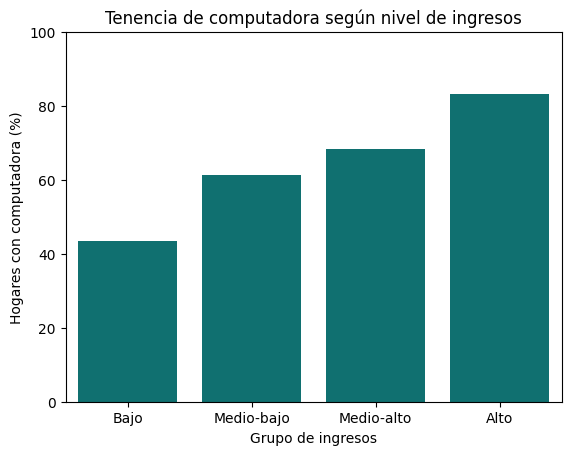

In [10]:
#Grafico relacion grupo de ingresos/hogares con computadora
sns.barplot(
    x=porcentajes.index,
    y=porcentajes[1.0],
    color="teal"
)

plt.title("Tenencia de computadora según nivel de ingresos")
plt.xlabel("Grupo de ingresos")
plt.ylabel("Hogares con computadora (%)")
plt.ylim(0, 100)
plt.show()

In [15]:
# relación existe entre el nivel educativo del jefe de hogar/ acceso a internet fijo
df_h2 = df_clean[["NIVEL_ED", "II7"]]

df_h2 = df_h2.dropna()

print("Cantidad de hogares:", len(df_h2))
print("Nivel educativo:")
print(df_h2["NIVEL_ED"].value_counts().sort_index())

print("\nAcceso a internet:")
print(df_h2["II7"].value_counts().sort_index())

Cantidad de hogares: 968
Nivel educativo:
NIVEL_ED
1.0     82
2.0    213
3.0    315
4.0    227
5.0    131
Name: count, dtype: int64

Acceso a internet:
II7
1.0    713
2.0    255
Name: count, dtype: int64


In [16]:
tabla_h2 = pd.crosstab(
    df_h2["NIVEL_ED"],
    df_h2["II7"]
)

tabla_h2

II7,1.0,2.0
NIVEL_ED,,
1.0,36,46
2.0,131,82
3.0,225,90
4.0,193,34
5.0,128,3


In [17]:
porcentajes_h2 = pd.crosstab(
    df_h2["NIVEL_ED"],
    df_h2["II7"],
    normalize="index"
) * 100

porcentajes_h2.round(2)

II7,1.0,2.0
NIVEL_ED,,
1.0,43.90,56.10
2.0,61.50,38.50
3.0,71.43,28.57
4.0,85.02,14.98
5.0,97.71,2.29


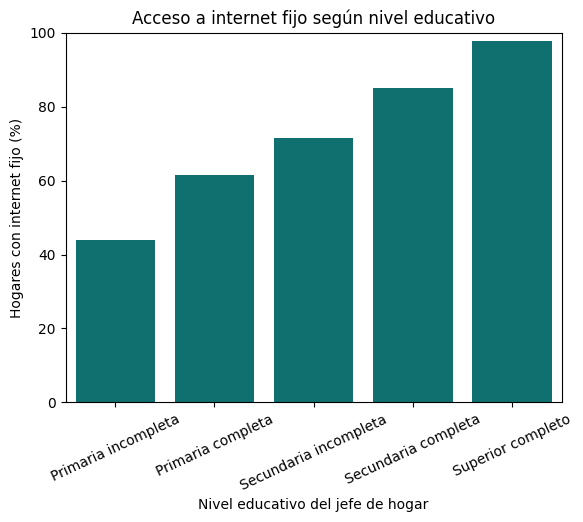

In [18]:
niveles = [
    "Primaria incompleta",
    "Primaria completa",
    "Secundaria incompleta",
    "Secundaria completa",
    "Superior completo"
]

sns.barplot(
    x=niveles,
    y=porcentajes_h2[1.0],
    color="teal"
)

plt.title("Acceso a internet fijo según nivel educativo")
plt.xlabel("Nivel educativo del jefe de hogar")
plt.ylabel("Hogares con internet fijo (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25)
plt.show()

In [19]:
#Relacion computadora/acceso a internet
df_h3 = df_clean[["II7", "IV12_3"]]

df_h3 = df_h3.dropna()

print("Cantidad de hogares:", len(df_h3))
print("Acceso a internet fijo:")
print(df_h3["II7"].value_counts().sort_index())

print("\nTenencia de computadora:")
print(df_h3["IV12_3"].value_counts().sort_index())

Cantidad de hogares: 937
Acceso a internet fijo:
II7
1.0    688
2.0    249
Name: count, dtype: int64

Tenencia de computadora:
IV12_3
1.0    596
2.0    341
Name: count, dtype: int64


In [20]:
tabla_h3 = pd.crosstab(
    df_h3["II7"],
    df_h3["IV12_3"]
)

tabla_h3

IV12_3,1.0,2.0
II7,,
1.0,464,224
2.0,132,117


In [24]:
porcentajes_h3 = pd.crosstab(
    df_h3["II7"],
    df_h3["IV12_3"],
    normalize="index"
) * 100

porcentajes_h3.round(2)

IV12_3,1.0,2.0
II7,,
1.0,67.44,32.56
2.0,53.01,46.99


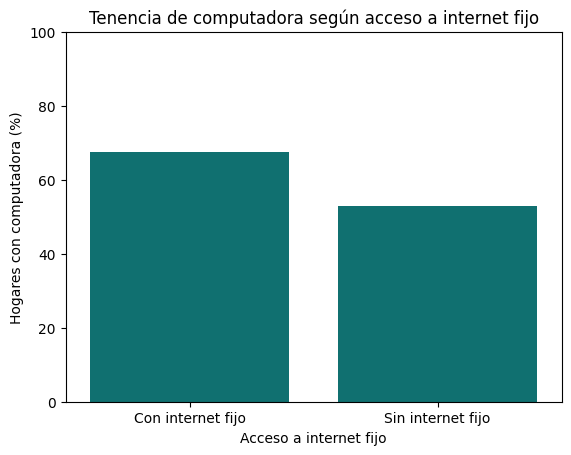

In [27]:
sns.barplot(
    x=["Con internet fijo", "Sin internet fijo"],
    y=porcentajes_h3[1.0],
    color="teal"
)

plt.title("Tenencia de computadora según acceso a internet fijo")
plt.xlabel("Acceso a internet fijo")
plt.ylabel("Hogares con computadora (%)")
plt.ylim(0, 100)
plt.show()